# Exercise 1.5 (Optional) | Reshaping Panel Data

In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# File Path
file_path = 'https://econ-0150.tayweid.io/data/'

In [2]:
# Load wide format data
percap = pd.read_csv(file_path + 'Coffee_Per_Cap.csv', index_col=0)
percap.head()

,Code,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
0,AUT,10.471682,10.073643,9.274671,10.132016,8.210563,7.639391,8.111554,8.185199,8.311615,...,6.478223,7.986517,9.032038,8.837449,7.968308,7.886425,8.193055,7.924919,7.954282,7.925747
2,BGR,0.701973,0.118160,1.229485,2.315778,2.508411,2.805117,1.764954,1.985066,2.354427,...,3.204609,2.939444,3.087920,3.460372,3.122950,3.393707,3.804809,3.518964,3.638415,3.638313
3,HRV,0.000000,0.000000,1.770175,1.721566,2.115208,3.740235,4.002548,4.776269,4.236414,...,5.168287,5.144112,5.061443,5.456226,5.209527,5.352550,5.461930,5.251506,5.283960,5.623266
4,CYP,2.358909,3.378966,2.887353,5.665956,3.197370,2.991589,3.545221,3.075308,3.017515,...,3.930296,4.244223,4.409644,4.575961,4.129159,4.699818,4.658226,4.815796,6.399575,5.615070
5,CZE,3.826444,3.055708,2.744419,2.602166,2.955411,2.968844,2.762902,2.824110,3.048267,...,2.692276,3.269790,3.910269,3.635059,5.689124,4.028045,4.576801,4.553333,6.536263,4.739563


## Reshaping: Wide to Long

Use `melt()` to convert wide format to long format when you need line plots.

In [3]:
# Melt to long format
percap_long = percap.melt(
    id_vars=['Code'],
    var_name='Year',
    value_name='Consumption'
)
percap_long.head(10)

,Code,Year,Consumption
0,AUT,1990,10.471682
1,BGR,1990,0.701973
2,HRV,1990,0.000000
3,CYP,1990,2.358909
4,CZE,1990,3.826444
5,DNK,1990,10.095432
6,EST,1990,0.000000
7,FIN,1990,12.874940
8,FRA,1990,5.380336
9,DEU,1990,5.498217


Now we can create a line plot with Year on the x-axis.

<Axes: xlabel='Year', ylabel='Consumption'>

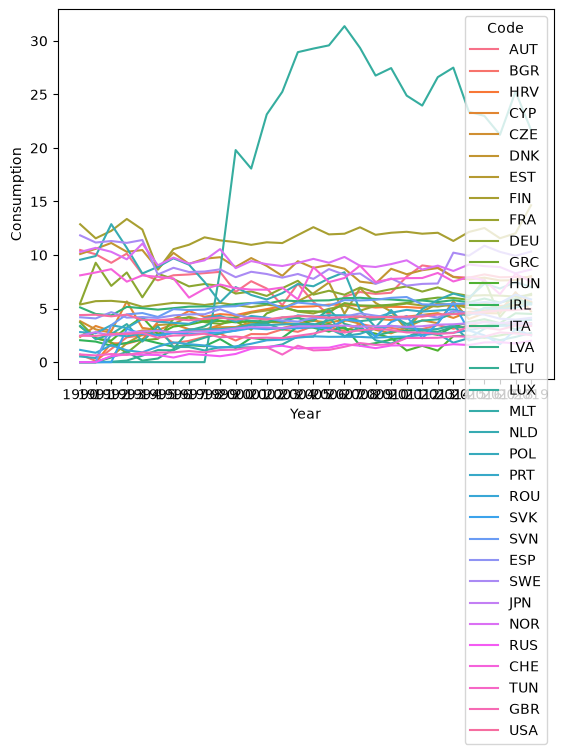

In [4]:
# Line plot from long format
sns.lineplot(percap_long, x='Year', y='Consumption', hue='Code')

## Reshaping: Long to Wide

Use `pivot()` to convert long format to wide format when you need boxplots or scatterplots.

In [5]:
# Pivot back to wide format
percap_wide = percap_long.pivot(
    index='Code',
    columns='Year',
    values='Consumption'
)
percap_wide.head()

Year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
Code,,,,,,,,,,,,,,,,,,,,,
AUT,10.471682,10.073643,9.274671,10.132016,8.210563,7.639391,8.111554,8.185199,8.311615,8.430589,...,6.478223,7.986517,9.032038,8.837449,7.968308,7.886425,8.193055,7.924919,7.954282,7.925747
BGR,0.701973,0.118160,1.229485,2.315778,2.508411,2.805117,1.764954,1.985066,2.354427,2.652661,...,3.204609,2.939444,3.087920,3.460372,3.122950,3.393707,3.804809,3.518964,3.638415,3.638313
CHE,8.103618,8.373557,8.683177,7.514847,8.098607,7.967972,7.822564,6.026318,6.843881,7.248049,...,7.759835,7.840859,7.855582,8.329474,7.532378,7.939731,7.638531,6.346547,8.244925,7.507627
CYP,2.358909,3.378966,2.887353,5.665956,3.197370,2.991589,3.545221,3.075308,3.017515,3.477888,...,3.930296,4.244223,4.409644,4.575961,4.129159,4.699818,4.658226,4.815796,6.399575,5.615070
CZE,3.826444,3.055708,2.744419,2.602166,2.955411,2.968844,2.762902,2.824110,3.048267,3.255587,...,2.692276,3.269790,3.910269,3.635059,5.689124,4.028045,4.576801,4.553333,6.536263,4.739563
